# MEC spikes → CEBRA model → latent output

Use CEBRA's public high-level estimator throughout. The two helpers in `mec_cebra.py` only load the original MATLAB file and bin spikes. No downstream analysis is included.

The defaults use CEBRA's published Neuropixels setup: **120 Hz raw spike counts**, **`offset40-model-4x-subsample`**, **offset 10**, and **batch size 512**. The encoder returns **30 Hz latents**. See `README.md` for sources and version details.

In [ ]:
# %pip install -r requirements.txt

## 1. Load and bin spikes

Set the local path to the same `27765_2.mat` file used for C3PO Figure 3. All 460 MEC units are retained in their original order. Bins remain separate across recording gaps; intervals shorter than 40 bins and incomplete final bins are omitted.

For your own spikes, replace `load_mec_spikes` with a list of spike-time arrays and an `(n_intervals, 2)` array of start/stop times, in seconds. For one continuous recording, use `intervals = [[start, stop]]`.

In [1]:
from pathlib import Path
import json

import cebra
import numpy as np

from mec_cebra import bin_spikes, load_mec_spikes

DATA_PATH = Path("/stelmo/sam/tmp/27765_2.mat")
OUTPUT_DIR = Path("results/cebra_time")
BIN_SECONDS = 1 / 120

spikes, intervals = load_mec_spikes(DATA_PATH)
count_blocks, time_blocks = bin_spikes(spikes, intervals, bin_seconds=BIN_SECONDS)
neural = np.concatenate(count_blocks)  # (n_time, n_units), raw float32 counts.
print(f"{neural.shape[0]:,} bins, {neural.shape[1]} units, {len(count_blocks)} intervals")

/home/sambray/mambaforge-pypy3/envs/cebra/lib/python3.15/site-packages/torch/jit/_script.py:1485: FutureWarning: `torch.jit.script` is not supported in Python 3.14+ and may break. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


155,084 bins, 460 units, 392 intervals


## 2. Create and train CEBRA-Time

Only spike counts enter `fit`. All other estimator parameters use CEBRA defaults, including GPU selection, optimizer, learning rate, hidden width, and temperature. Edit `output_dimension` to match your C3PO model.

**Gap limitation:** training concatenates intervals. The native high-level CEBRA-Time estimator has no segment-boundary argument, so training windows and positive pairs can cross junctions. Inference below processes each interval separately. This prevents crossing during inference but does not undo the influence of junctions during training.

In [2]:
# model = cebra.CEBRA(
#     model_architecture="offset40-model-4x-subsample",
#     conditional="time",
#     time_offsets=10,
#     batch_size=512,
#     output_dimension=16,
#     max_iterations=10_000,
#     verbose=True,
# )

model = cebra.CEBRA(
    model_architecture="offset1-model",
    conditional="time",
    time_offsets=2,
    batch_size=512,
    output_dimension=16,
    max_iterations=100_000,
    verbose=True,
)

# Temporal pairing constrained to the same continuous interval.
model.fit(neural,)



  0%|          | 0/100000 [00:00<?, ?it/s]/home/sambray/mambaforge-pypy3/envs/cebra/lib/python3.15/site-packages/triton/knobs.py:504: UserWarning: TRITON_DEFAULT_FP_FUSION is unset: defaulting to FP fusion ENABLED for backward compatibility in Triton 3.9. The default will change to DISABLED in Triton 3.10; set TRITON_DEFAULT_FP_FUSION=1 to keep fusion enabled or =0 to adopt the new default early and silence this warning.
  warn_once(FP_FUSION_DEFAULT_WARNING)
pos: -0.5680 neg:  6.3620 total:  5.7941 temperature:  1.0000: 100%|██████████| 100000/100000 [29:03<00:00, 57.37it/s]


,conditional,'time'
,time_offsets,2
,max_iterations,100000
,batch_size,512
,output_dimension,16
,verbose,True
,optimizer_kwargs,"(('betas', ...), ...)"
,model_architecture,'offset1-model'
,device,'cuda_if_available'
,criterion,'infonce'
,distance,'cosine'


## 3. Infer and save

`latent` is the native CEBRA embedding, shaped `(n_latent_time, n_latent)`, aligned row-for-row with `time` and `segment_id`. The subsampling encoder returns one row per four input bins, so timestamps use every fourth input-bin center within each interval. Each interval uses CEBRA's default edge padding independently.

In [3]:
latent_blocks = [model.transform(block) for block in count_blocks]
latent = np.concatenate(latent_blocks)
time = np.concatenate([block[:] for block in time_blocks])
segment_id = np.repeat(np.arange(len(latent_blocks)), [len(x) for x in latent_blocks])
assert len(latent) == len(time) == len(segment_id)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
model.save(str(OUTPUT_DIR / "cebra_model.pt"))
np.savez_compressed(
    OUTPUT_DIR / "cebra_latent.npz",
    latent=latent,
    time=time,
    segment_id=segment_id,
    unit_index=np.arange(neural.shape[1]),
    input_bin_seconds=BIN_SECONDS,
    latent_step_seconds=4 * BIN_SECONDS,
)
(OUTPUT_DIR / "cebra_parameters.json").write_text(
    json.dumps(
        {"cebra_version": cebra.__version__, "model": model.get_params()}, indent=2
    ),
    encoding="utf-8",
)
print(f"Saved latent {latent.shape} and model to {OUTPUT_DIR}")

Saved latent (155084, 16) and model to results/cebra_time


Reload with `model = cebra.CEBRA.load(str(OUTPUT_DIR / "cebra_model.pt"))` and `output = np.load(OUTPUT_DIR / "cebra_latent.npz")`.

For already-binned **continuous** data, use the estimator directly: `model.fit(neural)` followed by `latent = model.transform(neural)`. Align the resulting latents to `input_time[::4]`.

In [4]:
latent.shape

(38915, 16)

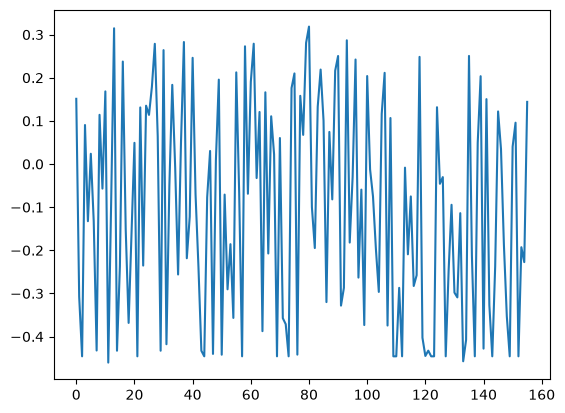

In [4]:
import matplotlib.pyplot as plt
plt.plot(latent[::1000, 2])

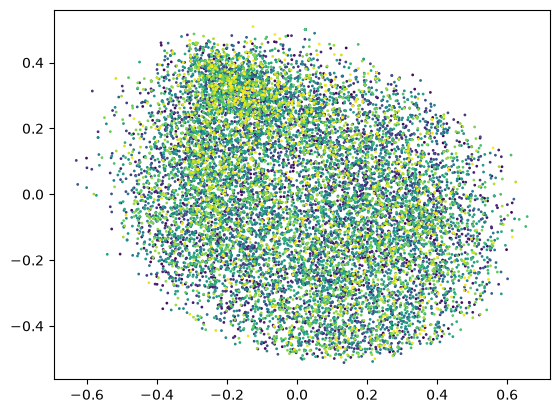

In [5]:
s=10

plt.scatter(latent[::s,0], latent[::s,5], c=time[::s], cmap='viridis', s=1)